In [13]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from superfv.tools.stability_analysis.variables import a, k, h, theta
from superfv.tools.stability_analysis.fv_advection import derive_fv_upwind_Omega_h_over_a, derive_fv_upwind_rhs, inject_harmonic_modes

hk = sp.symbols("hk", real=True)

In [14]:
def derive_fv_upwind_knum_error_func(p):
    factor = derive_fv_upwind_Omega_h_over_a(p).subs(theta, k * h) * a / h
    error = factor / (-sp.I * a * k) - 1
    error = error.subs(h * k, hk)
    error_func = sp.lambdify(hk, error, modules="numpy")
    return error_func

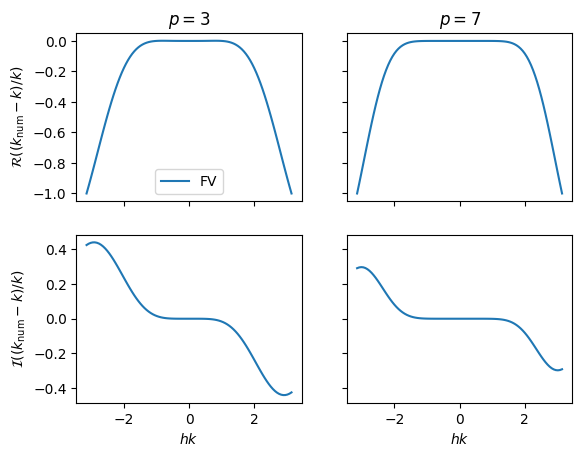

In [15]:
hk_array = np.linspace(-np.pi, np.pi, 100)
trace_p3 = derive_fv_upwind_knum_error_func(3)(hk_array)
trace_p7 = derive_fv_upwind_knum_error_func(7)(hk_array)

fig, axs = plt.subplots(2, 2, sharex=True, sharey='row')
for ax in axs[1,:]:
    ax.set_xlabel(r"$hk$")
axs[0, 0].set_ylabel(r"$\mathcal{R}((k_{\text{num}}-k)/k)$")
axs[1, 0].set_ylabel(r"$\mathcal{I}((k_{\text{num}}-k)/k)$")
axs[0, 0].set_title(r"$p=3$")
axs[0, 1].set_title(r"$p=7$")

axs[0, 0].plot(hk_array, trace_p3.real, label="FV")
axs[0, 1].plot(hk_array, trace_p7.real)
axs[1, 0].plot(hk_array, trace_p3.imag)
axs[1, 1].plot(hk_array, trace_p7.imag)

axs[0, 0].legend()